# Diagnóstico y preparación de datos: Student Performance Factors
**Autor:** Isaac Esquivel Ruiz  
**Fecha de consulta:** 30 de septiembre de 2026 (México)  
**Herramientas:** Python, Pandas, NumPy, Matplotlib y Scikit-learn.

## 1. Fuente, vigencia y contexto
| Dato | Información |
|---|---|
| Nombre | Student Performance Factors Dataset |
| Fuente y autor | Kaggle, Mosap Abdel-Ghany |
| Acceso | https://www.kaggle.com/datasets/mosapabdelghany/student-performance-factors-dataset |
| Última actualización reportada | **16 de octubre de 2025, 11:31:36.033 UTC**, versión 1 |
| Evidencia de actualización | Campo `lastUpdated` de la [API pública de Kaggle](https://www.kaggle.com/api/v1/datasets/list?search=student-performance-factors-dataset), consultado para esta actividad |
| Vigencia | Aproximadamente 11 meses y medio antes de la consulta; cumple el máximo de tres años |
| Archivo analizado | CSV proporcionado para la actividad: `StudentPerformanceFactors (3).csv`; sus datos coinciden con la descarga de Kaggle versión 1 |

Cada fila representa **un registro de estudiante**, con hábitos de estudio, asistencia, antecedentes académicos y factores familiares y escolares. No existe un identificador que permita confirmar si cada registro corresponde a una persona distinta. La variable de interés es **Exam_Score**, un puntaje numérico, por lo que una tarea posterior sería de **regresión supervisada**.

Un modelo podría estimar el puntaje y apoyar la identificación de estudiantes que podrían necesitar apoyo académico. Las asociaciones no demuestran causalidad. La ficha y el archivo no permiten confirmar aquí la representatividad de la muestra ni su procedimiento de recolección. La fecha de publicación/actualización tampoco demuestra que las observaciones sean recientes.

**Uso en Colab:** abre este notebook y selecciona **Entorno de ejecución → Ejecutar todas**. Si el CSV no está cargado, aparecerá el selector para subir el archivo original. No subas el CSV preparado como entrada. En Jupyter, coloca el original junto al notebook. No se entrena ningún modelo en esta actividad.

In [3]:
from pathlib import Path
from datetime import date
import io, re, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string() if hasattr(obj, 'to_string') else obj)

pd.set_option('display.max_columns', 35)
pd.set_option('display.max_colwidth', 110)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
print('Python:', sys.version.split()[0], '| Pandas:', pd.__version__,
      '| NumPy:', np.__version__, '| Scikit-learn:', sklearn.__version__)
consulta = date(2026, 9, 30)
actualizacion = date(2025, 10, 16)
assert date(2023, 9, 30) <= actualizacion <= consulta
print('Antigüedad:', (consulta - actualizacion).days, 'días. Cumple el máximo de 3 años.')

Python: 3.13.15 | Pandas: 2.2.3 | NumPy: 2.1.3 | Scikit-learn: 1.6.1
Antigüedad: 349 días. Cumple el máximo de 3 años.


## 2. Carga y estructura inicial
Se conserva `df_original` sin modificaciones. La huella SHA-256 permite identificar exactamente los bytes del archivo usado. Se revisan dimensiones, tipos, faltantes, duplicados, valores únicos, ejemplos y estadísticas antes de tomar decisiones.

In [4]:
# Puedes indicar otra ruta al CSV original si trabajas fuera de Colab.
RUTA_CSV = None
candidatos = [Path('StudentPerformanceFactors (3).csv'), Path('StudentPerformanceFactors.csv')]
ruta = Path(RUTA_CSV) if RUTA_CSV else next((p for p in candidatos if p.exists()), None)
if ruta is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Coloca el CSV original junto al notebook o define RUTA_CSV.')
    subidos = files.upload()
    csv_subidos = [n for n in subidos if n.lower().endswith('.csv')]
    if len(csv_subidos) != 1:
        raise ValueError('Sube exactamente un CSV: el archivo ORIGINAL.')
    ruta = Path(csv_subidos[0])
contenido = ruta.read_bytes()
sha = hashlib.sha256(contenido).hexdigest()
df_original = pd.read_csv(io.BytesIO(contenido))
print('Archivo:', ruta.name, '| SHA-256:', sha)
print('Filas:', df_original.shape[0], '| Columnas:', df_original.shape[1])
print('Variables:', ', '.join(df_original.columns))
display(df_original.head())
df_original.info()
resumen_inicial = pd.DataFrame({
    'Tipo': df_original.dtypes.astype(str),
    'Faltantes': df_original.isna().sum(),
    'Faltantes (%)': df_original.isna().mean().mul(100).round(2),
    'Únicos sin NaN': df_original.nunique(dropna=True)
})
display(resumen_inicial)
print('Registros duplicados:', int(df_original.duplicated().sum()))
display(df_original.describe().T.round(3))
display(df_original.describe(include=['object', 'string']).T)
print(f'Interpretación inicial: {len(df_original):,} registros, {df_original.shape[1]} variables, '
      f'{df_original.isna().sum().sum()} celdas faltantes y {df_original.duplicated().sum()} duplicados.')
print('La mezcla de variables numéricas y categóricas requiere tratamientos distintos. '
      'Los faltantes están en Teacher_Quality, Parental_Education_Level y Distance_from_Home. '
      'Exam_Score llega a 101; se revisa antes de preparar el objetivo.')

Saving StudentPerformanceFactors (3).csv to StudentPerformanceFactors (3).csv
Archivo: StudentPerformanceFactors (3).csv | SHA-256: e8df8c4148ef83fb295ca1c092f2c6ee15272c0a8e3018b769a788ab50e96e97
Filas: 6607 | Columnas: 20
Variables: Hours_Studied, Attendance, Parental_Involvement, Access_to_Resources, Extracurricular_Activities, Sleep_Hours, Previous_Scores, Motivation_Level, Internet_Access, Tutoring_Sessions, Family_Income, Teacher_Quality, School_Type, Peer_Influence, Physical_Activity, Learning_Disabilities, Parental_Education_Level, Distance_from_Home, Gender, Exam_Score


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

,Tipo,Faltantes,Faltantes (%),Únicos sin NaN
Hours_Studied,int64,0,0.00,41
Attendance,int64,0,0.00,41
Parental_Involvement,object,0,0.00,3
Access_to_Resources,object,0,0.00,3
Extracurricular_Activities,object,0,0.00,2
Sleep_Hours,int64,0,0.00,7
Previous_Scores,int64,0,0.00,51
Motivation_Level,object,0,0.00,3
Internet_Access,object,0,0.00,2
Tutoring_Sessions,int64,0,0.00,9


Registros duplicados: 0


,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.975,5.991,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.977,11.547,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6607.0,7.029,1.468,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,75.071,14.400,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6607.0,1.494,1.231,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6607.0,2.968,1.031,0.0,2.0,3.0,4.0,6.0
Exam_Score,6607.0,67.236,3.890,55.0,65.0,67.0,69.0,101.0


,count,unique,top,freq
Parental_Involvement,6607,3,Medium,3362
Access_to_Resources,6607,3,Medium,3319
Extracurricular_Activities,6607,2,Yes,3938
Motivation_Level,6607,3,Medium,3351
Internet_Access,6607,2,Yes,6108
Family_Income,6607,3,Low,2672
Teacher_Quality,6529,3,Medium,3925
School_Type,6607,2,Public,4598
Peer_Influence,6607,3,Positive,2638
Learning_Disabilities,6607,2,No,5912


Interpretación inicial: 6,607 registros, 20 variables, 235 celdas faltantes y 0 duplicados.
La mezcla de variables numéricas y categóricas requiere tratamientos distintos. Los faltantes están en Teacher_Quality, Parental_Education_Level y Distance_from_Home. Exam_Score llega a 101; se revisa antes de preparar el objetivo.


## 3. Diagnóstico de calidad y reglas explícitas
Se distinguen problemas **observados** de comprobaciones preventivas. No se inventan errores de escritura ni identificadores. Un valor atípico por IQR no es necesariamente imposible.

**Supuesto de trabajo:** se considera `Exam_Score` en escala 0–100. El registro con 101 se separa para revisión, sin sustituirlo arbitrariamente por 100. Como no se confirmó una regla sobre puntos extra, este límite es configurable: si la institución confirma que 101 es válido, cambia `MAX_EXAM_SCORE = None` y ejecuta todo de nuevo. Para asistencia y puntaje previo se usa 0–100; para sueño, 0–24 horas diarias; para estudio, 0–168 horas semanales. Tutorías y actividad física no pueden ser negativas; no se inventa un límite superior para estas dos variables.

In [5]:
NUMERICAS = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
             'Tutoring_Sessions', 'Physical_Activity']
ORDENES = {
    'Parental_Involvement': ['Low', 'Medium', 'High'],
    'Access_to_Resources': ['Low', 'Medium', 'High'],
    'Motivation_Level': ['Low', 'Medium', 'High'],
    'Family_Income': ['Low', 'Medium', 'High'],
    'Teacher_Quality': ['Low', 'Medium', 'High'],
    'Parental_Education_Level': ['High School', 'College', 'Postgraduate'],
    'Distance_from_Home': ['Near', 'Moderate', 'Far']
}
NOMINALES = {
    'Extracurricular_Activities': ['No', 'Yes'], 'Internet_Access': ['No', 'Yes'],
    'School_Type': ['Private', 'Public'], 'Peer_Influence': ['Negative', 'Neutral', 'Positive'],
    'Learning_Disabilities': ['No', 'Yes'], 'Gender': ['Female', 'Male']
}
CATEGORIAS = {**ORDENES, **NOMINALES}
OBJETIVO = 'Exam_Score'
MAX_EXAM_SCORE = 100
RANGOS = {'Hours_Studied': (0, 168), 'Attendance': (0, 100), 'Sleep_Hours': (0, 24),
          'Previous_Scores': (0, 100), 'Tutoring_Sessions': (0, np.inf),
          'Physical_Activity': (0, np.inf), OBJETIVO: (0, MAX_EXAM_SCORE or np.inf)}

def normalizar_texto(valor):
    return re.sub(r'\s+', ' ', str(valor).strip()).casefold()

def mascara_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5*iqr) | (serie > q3 + 1.5*iqr)

# Nombres consistentes, sin alterar etiquetas que ya están correctas.
df = df_original.copy()
renombrado = {c: re.sub(r'\s+', '_', c.strip()) for c in df.columns}
df = df.rename(columns=renombrado)
assert not df.columns.duplicated().any(), 'Hay nombres de columnas repetidos.'
esperadas = NUMERICAS + list(CATEGORIAS) + [OBJETIVO]
assert set(df.columns) == set(esperadas), 'El esquema no corresponde al CSV original esperado.'

hallazgos = []
def registrar(problema, variable, evidencia, tratamiento):
    hallazgos.append([problema, variable, evidencia, tratamiento])
registrar('Nombres de columnas', 'Todas', f'{sum(k != v for k,v in renombrado.items())} requieren ajuste',
          'Quitar espacios externos y sustituir espacios internos por guion bajo.')
for c in df.columns:
    n = int(df[c].isna().sum())
    if n:
        registrar('Valores faltantes', c, f'{n} ({n/len(df):.2%})',
                  'Imputación por moda dentro del Pipeline; conservar registros.')
registrar('Duplicados exactos', 'Registro completo', str(int(df.duplicated().sum())),
          'Eliminar solamente copias exactas si se encuentran.')
for c in NUMERICAS + [OBJETIVO]:
    convertido = pd.to_numeric(df[c], errors='coerce')
    ilegibles = int((df[c].notna() & convertido.isna()).sum())
    fuera = convertido.notna() & ~convertido.between(*RANGOS[c])
    registrar('Tipo numérico y rango', c,
              f'tipo={df[c].dtype}; ilegibles={ilegibles}; fuera de rango={int(fuera.sum())}',
              'Convertir a número; separar objetivos inválidos; predictores inválidos a NaN y mediana.')
    registrar('Valores extremos (1.5 × IQR)', c, f'{int(mascara_iqr(convertido).sum())} observaciones',
              'Conservar si son plausibles; no borrar por ser atípicos.')
for c, valores in CATEGORIAS.items():
    s = df[c].dropna().astype(str)
    mapa = {normalizar_texto(v): v for v in valores}
    canonicas = s.map(lambda x: mapa.get(normalizar_texto(x), None))
    cambios = int(((s != canonicas) & canonicas.notna()).sum())
    desconocidas = sorted(s[canonicas.isna()].unique().tolist())
    registrar('Categorías, espacios y mayúsculas', c,
              f'{cambios} ajustes; desconocidas={desconocidas}',
              'Normalizar contra catálogo; detener ejecución ante categorías no documentadas.')
constantes = df.columns[df.nunique(dropna=True) <= 1].tolist()
unicas = df.columns[df.nunique(dropna=True) == len(df)].tolist()
registrar('Variables constantes / posibles identificadores', 'Todas',
          f'Constantes={constantes}; únicas por fila={unicas}; no hay columna ID en el esquema.',
          'No eliminar ninguna columna: todas tienen una interpretación útil.')
tabla_hallazgos = pd.DataFrame(hallazgos, columns=[
    'Problema detectado', 'Variable afectada', 'Evidencia', 'Tratamiento propuesto'])
display(tabla_hallazgos)

,Problema detectado,Variable afectada,Evidencia,Tratamiento propuesto
0,Nombres de columnas,Todas,0 requieren ajuste,Quitar espacios externos y sustituir espacios internos por guion bajo.
1,Valores faltantes,Teacher_Quality,78 (1.18%),Imputación por moda dentro del Pipeline; conservar registros.
2,Valores faltantes,Parental_Education_Level,90 (1.36%),Imputación por moda dentro del Pipeline; conservar registros.
3,Valores faltantes,Distance_from_Home,67 (1.01%),Imputación por moda dentro del Pipeline; conservar registros.
4,Duplicados exactos,Registro completo,0,Eliminar solamente copias exactas si se encuentran.
5,Tipo numérico y rango,Hours_Studied,tipo=int64; ilegibles=0; fuera de rango=0,Convertir a número; separar objetivos inválidos; predictores inválidos a NaN y mediana.
6,Valores extremos (1.5 × IQR),Hours_Studied,43 observaciones,Conservar si son plausibles; no borrar por ser atípicos.
7,Tipo numérico y rango,Attendance,tipo=int64; ilegibles=0; fuera de rango=0,Convertir a número; separar objetivos inválidos; predictores inválidos a NaN y mediana.
8,Valores extremos (1.5 × IQR),Attendance,0 observaciones,Conservar si son plausibles; no borrar por ser atípicos.
9,Tipo numérico y rango,Sleep_Hours,tipo=int64; ilegibles=0; fuera de rango=0,Convertir a número; separar objetivos inválidos; predictores inválidos a NaN y mediana.


## 4. Limpieza básica y registro de cambios
Se normalizan nombres y categorías, se comprueban tipos y se quitan únicamente duplicados exactos. Estas operaciones son preventivas: el archivo recibido ya tiene nombres y categorías consistentes y tipos numéricos correctos. Se muestra cuántas celdas realmente cambiaron.

Los registros con objetivo ausente o inválido no pueden usarse como ejemplos supervisados confiables y se guardan por separado. Los predictores inválidos se convierten en faltantes para imputarlos. La imputación se realizará **dentro del Pipeline** de la sección 8: mediana para números y moda para categorías. De esta manera no se eliminan las filas que tienen información categórica incompleta.

In [6]:
bitacora = []
for c in NUMERICAS + [OBJETIVO]:
    antes = df[c].copy()
    df[c] = pd.to_numeric(df[c], errors='coerce')
    bitacora.append([f'Conversión numérica: {c}', int((antes.notna() & df[c].isna()).sum()),
                     'Valores ilegibles convertidos en NaN; 0 si no había problemas.'])
for c, valores in CATEGORIAS.items():
    mapa = {normalizar_texto(v): v for v in valores}
    antes = df[c].copy()
    df[c] = df[c].map(lambda x: np.nan if pd.isna(x) or str(x).strip() == ''
                     else mapa.get(normalizar_texto(x), str(x).strip()))
    desconocidas = set(df[c].dropna()) - set(valores)
    if desconocidas:
        raise ValueError(f'Revisar categorías no documentadas en {c}: {desconocidas}')
    cambios = int((antes.fillna('<NA>') != df[c].fillna('<NA>')).sum())
    bitacora.append([f'Normalización: {c}', cambios, 'Espacios, mayúsculas y categorías canónicas.'])
ndup = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
bitacora.append(['Duplicados exactos eliminados', ndup, 'Una copia por combinación completa.'])
objetivo_invalido = df[OBJETIVO].isna() | ~df[OBJETIVO].between(*RANGOS[OBJETIVO])
registros_revision = df.loc[objetivo_invalido].copy()
df = df.loc[~objetivo_invalido].copy()
bitacora.append(['Registros separados por objetivo inválido', len(registros_revision),
                 'Escala asumida 0–100; no se inventa un puntaje corregido.'])
for c in NUMERICAS:
    invalido = df[c].notna() & ~df[c].between(*RANGOS[c])
    df.loc[invalido, c] = np.nan
    bitacora.append([f'Rango imposible: {c}', int(invalido.sum()), 'Convertido en NaN para mediana.'])
df = df.reset_index(drop=True)
display(pd.DataFrame(bitacora, columns=['Operación', 'Cantidad', 'Justificación / significado']))
print('Registros separados para revisión:')
display(registros_revision)
print('Filas conservadas:', len(df), '| Faltantes pendientes de imputación:', int(df.isna().sum().sum()))
print('Ninguna columna fue eliminada. Los atípicos plausibles se conservan.')

,Operación,Cantidad,Justificación / significado
0,Conversión numérica: Hours_Studied,0,Valores ilegibles convertidos en NaN; 0 si no había problemas.
1,Conversión numérica: Attendance,0,Valores ilegibles convertidos en NaN; 0 si no había problemas.
2,Conversión numérica: Sleep_Hours,0,Valores ilegibles convertidos en NaN; 0 si no había problemas.
3,Conversión numérica: Previous_Scores,0,Valores ilegibles convertidos en NaN; 0 si no había problemas.
4,Conversión numérica: Tutoring_Sessions,0,Valores ilegibles convertidos en NaN; 0 si no había problemas.
5,Conversión numérica: Physical_Activity,0,Valores ilegibles convertidos en NaN; 0 si no había problemas.
6,Conversión numérica: Exam_Score,0,Valores ilegibles convertidos en NaN; 0 si no había problemas.
7,Normalización: Parental_Involvement,0,"Espacios, mayúsculas y categorías canónicas."
8,Normalización: Access_to_Resources,0,"Espacios, mayúsculas y categorías canónicas."
9,Normalización: Motivation_Level,0,"Espacios, mayúsculas y categorías canónicas."


Registros separados para revisión:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


Filas conservadas: 6606 | Faltantes pendientes de imputación: 235
Ninguna columna fue eliminada. Los atípicos plausibles se conservan.


## 5. Distribución de la variable objetivo: Exam_Score
Se calcula la estadística descriptiva original y después del filtro, incluyendo mediana, desviación estándar, cuartiles, asimetría y número de atípicos por IQR. Las gráficas muestran el diagnóstico **antes** de separar el 101, para que la anomalía siga siendo visible.

,Original,Tras limpieza de rangos
count,6607.000,6606.000
mean,67.236,67.231
std,3.890,3.869
min,55.000,55.000
25%,65.000,65.000
50%,67.000,67.000
75%,69.000,69.000
max,101.000,100.000
mediana,67.000,67.000
asimetría,1.645,1.576


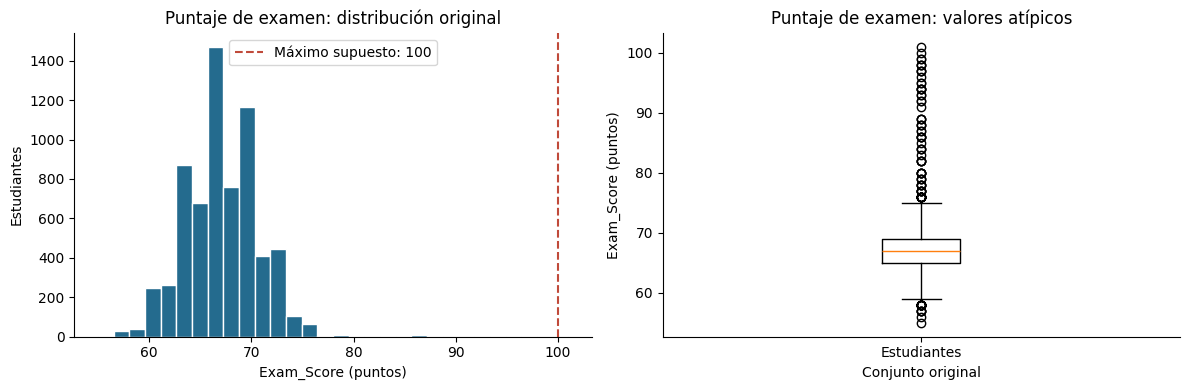

Interpretación del histograma: la mayoría de los puntajes se concentra alrededor de 65–69, con una cola hacia puntajes altos. La asimetría positiva impide asumir una distribución normal.
Interpretación del diagrama de caja: hay 104 observaciones fuera de los límites IQR en el original. Solo el 101 se separa bajo el supuesto 0–100; el resto puede representar desempeño real. Los pocos puntajes altos pueden hacer más difícil predecir los extremos y elevar errores como RMSE.


In [7]:
def estadisticas(s):
    s = pd.to_numeric(s, errors='coerce')
    resultado = s.describe()
    resultado['mediana'] = s.median()
    resultado['asimetría'] = s.skew()
    resultado['atípicos_IQR'] = int(mascara_iqr(s).sum())
    return resultado

display(pd.DataFrame({'Original': estadisticas(df_original[OBJETIVO]),
                      'Tras limpieza de rangos': estadisticas(df[OBJETIVO])}).round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df_original[OBJETIVO], bins=30, color='#246B8E', edgecolor='white')
ax[0].set(title='Puntaje de examen: distribución original', xlabel='Exam_Score (puntos)', ylabel='Estudiantes')
ax[0].axvline(100, color='#C04A3A', linestyle='--', label='Máximo supuesto: 100')
ax[0].legend()
ax[1].boxplot(df_original[OBJETIVO], vert=True)
ax[1].set(title='Puntaje de examen: valores atípicos', xlabel='Conjunto original', ylabel='Exam_Score (puntos)')
ax[1].set_xticks([1], ['Estudiantes'])
plt.tight_layout(); plt.show()
print('Interpretación del histograma: la mayoría de los puntajes se concentra alrededor de 65–69, '
      'con una cola hacia puntajes altos. La asimetría positiva impide asumir una distribución normal.')
print('Interpretación del diagrama de caja: hay 104 observaciones fuera de los límites IQR en el original. '
      'Solo el 101 se separa bajo el supuesto 0–100; el resto puede representar desempeño real. '
      'Los pocos puntajes altos pueden hacer más difícil predecir los extremos y elevar errores como RMSE.')

## 6. Exploración ampliada: dos variables numéricas
Se analizan `Hours_Studied` y `Attendance` sobre las filas conservadas. El histograma muestra dónde se concentran los valores y el diagrama de caja ayuda a detectar extremos. No se utiliza la regla IQR como una orden automática de borrado.

,count,mean,std,min,25%,50%,75%,max,mediana,asimetría,atípicos_IQR
Hours_Studied,6606.0,19.974,5.990,1.0,16.0,20.0,24.0,44.0,20.0,0.014,43.0
Attendance,6606.0,79.975,11.546,60.0,70.0,80.0,90.0,100.0,80.0,0.014,0.0


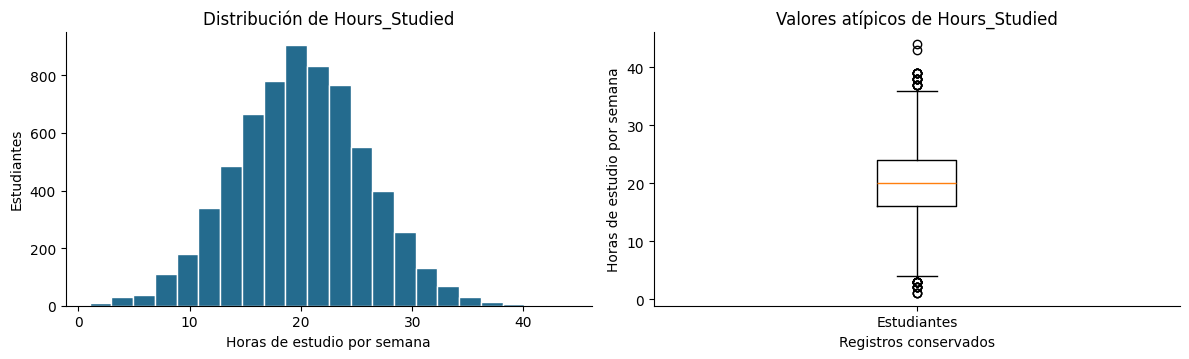

Hours_Studied: mediana=20.00; rango=1–44; atípicos IQR=43.
Histograma: concentración alrededor de 20 horas y forma aproximadamente simétrica. Caja: aparecen tiempos bajos y altos poco frecuentes, pero plausibles dentro de una semana; se conservan.


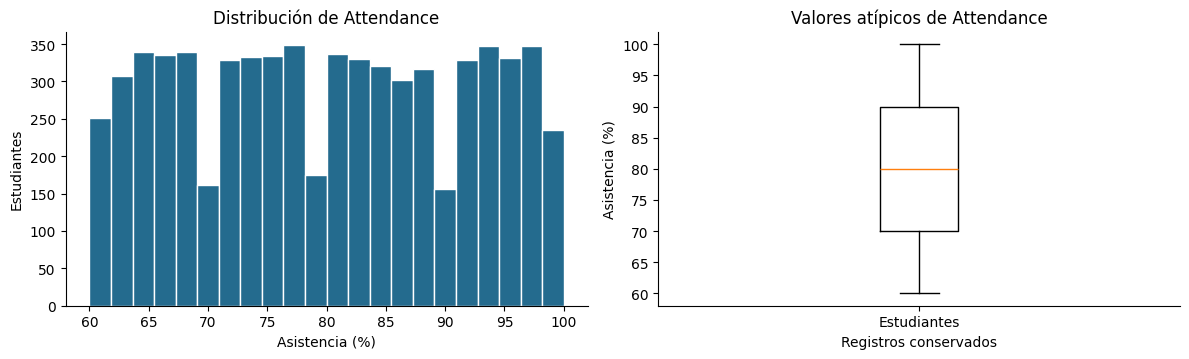

Attendance: mediana=80.00; rango=60–100; atípicos IQR=0.
Histograma: la asistencia se distribuye entre 60% y 100%, sin una concentración tan marcada. Caja: no aparecen atípicos IQR. El rango observado no incluye asistencia menor a 60%, lo que limita la generalización a estudiantes con inasistencia extrema.


In [8]:
display(pd.DataFrame({c: estadisticas(df[c]) for c in ['Hours_Studied', 'Attendance']}).T.round(3))
for c, etiqueta in [('Hours_Studied', 'Horas de estudio por semana'), ('Attendance', 'Asistencia (%)')]:
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.7))
    ax[0].hist(df[c].dropna(), bins=22, color='#246B8E', edgecolor='white')
    ax[0].set(title=f'Distribución de {c}', xlabel=etiqueta, ylabel='Estudiantes')
    ax[1].boxplot(df[c].dropna(), vert=True)
    ax[1].set(title=f'Valores atípicos de {c}', xlabel='Registros conservados', ylabel=etiqueta)
    ax[1].set_xticks([1], ['Estudiantes'])
    plt.tight_layout(); plt.show()
    print(f'{c}: mediana={df[c].median():.2f}; rango={df[c].min():.0f}–{df[c].max():.0f}; '
          f'atípicos IQR={int(mascara_iqr(df[c]).sum())}.')
    if c == 'Hours_Studied':
        print('Histograma: concentración alrededor de 20 horas y forma aproximadamente simétrica. '
              'Caja: aparecen tiempos bajos y altos poco frecuentes, pero plausibles dentro de una semana; se conservan.')
    else:
        print('Histograma: la asistencia se distribuye entre 60% y 100%, sin una concentración tan marcada. '
              'Caja: no aparecen atípicos IQR. El rango observado no incluye asistencia menor a 60%, '
              'lo que limita la generalización a estudiantes con inasistencia extrema.')

## 7. Exploración ampliada: variables categóricas
Se analizan `School_Type` y `Parental_Involvement`, y además `Teacher_Quality` para visualizar uno de los problemas de datos faltantes. Se consideran poco comunes las categorías con menos de 5% de los registros; este umbral es descriptivo y no implica agruparlas ni eliminarlas. Los faltantes se muestran separados, antes de imputarlos.

,Frecuencia,Porcentaje,Poco común (<5%)
School_Type,,,
Public,4597,69.59,False
Private,2009,30.41,False


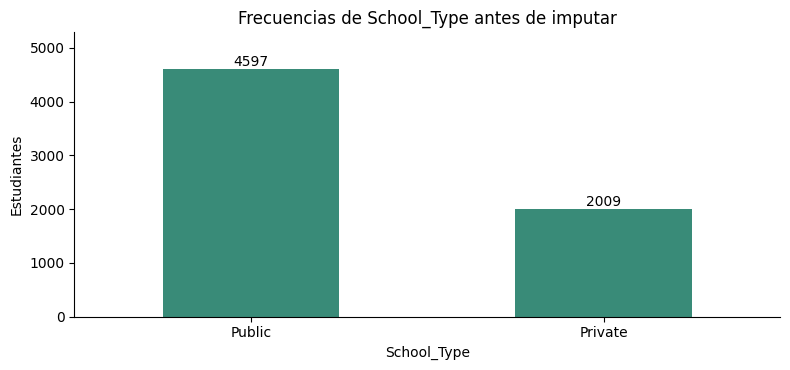

Interpretación: la categoría más frecuente es Public (69.6%). Categorías reales poco comunes: ninguna.
Predominan las escuelas públicas; la diferencia de tamaño debe considerarse al evaluar errores por grupo. Public y Private son etiquetas sin jerarquía.


,Frecuencia,Porcentaje,Poco común (<5%)
Parental_Involvement,,,
Medium,3362,50.89,False
High,1908,28.88,False
Low,1336,20.22,False


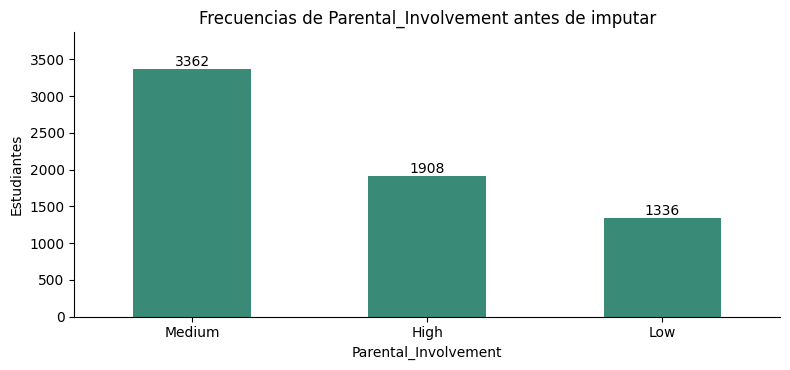

Interpretación: la categoría más frecuente es Medium (50.9%). Categorías reales poco comunes: ninguna.
Los niveles Low, Medium y High tienen un orden claro. No se detectaron variantes inconsistentes de escritura.


,Frecuencia,Porcentaje,Poco común (<5%)
Teacher_Quality,,,
Medium,3925,59.42,False
High,1946,29.46,False
Low,657,9.95,False
Sin dato,78,1.18,True


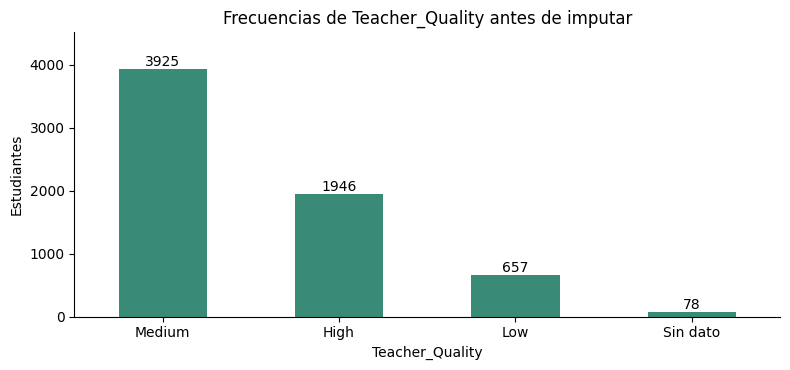

Interpretación: la categoría más frecuente es Medium (59.4%). Categorías reales poco comunes: ninguna.
Sin dato representa ausencia de información, no una calidad docente inferior. La imputación por moda aumentará la categoría predominante y puede reducir diversidad.


In [9]:
for c in ['School_Type', 'Parental_Involvement', 'Teacher_Quality']:
    conteos = df[c].fillna('Sin dato').value_counts()
    frecuencias = pd.DataFrame({'Frecuencia': conteos, 'Porcentaje': conteos/len(df)*100})
    frecuencias['Poco común (<5%)'] = frecuencias['Porcentaje'] < 5
    display(frecuencias.round(2))
    ax = conteos.plot.bar(color='#398B78', figsize=(8, 3.8), rot=0)
    ax.set(title=f'Frecuencias de {c} antes de imputar', xlabel=c, ylabel='Estudiantes')
    for i, n in enumerate(conteos):
        ax.text(i, n, str(n), ha='center', va='bottom')
    ax.set_ylim(0, conteos.max()*1.15)
    plt.tight_layout(); plt.show()
    reales = frecuencias.drop(index='Sin dato', errors='ignore')
    raras = reales.index[reales['Poco común (<5%)']].tolist()
    print(f'Interpretación: la categoría más frecuente es {conteos.index[0]} '
          f'({conteos.iloc[0]/len(df):.1%}). Categorías reales poco comunes: {raras or "ninguna"}.')
    if c == 'School_Type':
        print('Predominan las escuelas públicas; la diferencia de tamaño debe considerarse al evaluar errores por grupo. '
              'Public y Private son etiquetas sin jerarquía.')
    elif c == 'Parental_Involvement':
        print('Los niveles Low, Medium y High tienen un orden claro. No se detectaron variantes inconsistentes de escritura.')
    else:
        print('Sin dato representa ausencia de información, no una calidad docente inferior. '
              'La imputación por moda aumentará la categoría predominante y puede reducir diversidad.')

## 8. Codificación, imputación y escalamiento reproducibles
Se separa `Exam_Score` como `y`, sin escalarla ni imputarla. Todas las otras columnas se preparan mediante `ColumnTransformer` y tres `Pipeline`:

| Grupo | Variables | Tratamiento | Motivo |
|---|---|---|---|
| Numéricas | Hours_Studied, Attendance, Sleep_Hours, Previous_Scores, Tutoring_Sessions, Physical_Activity | Mediana si falta algún valor y StandardScaler | Mantener registros y expresar variables en unidades comparables |
| Ordinales | Parental_Involvement, Access_to_Resources, Motivation_Level, Family_Income, Teacher_Quality, Parental_Education_Level, Distance_from_Home | Moda y OrdinalEncoder, con orden explícito | Conservar la jerarquía de las categorías |
| Nominales | Extracurricular_Activities, Internet_Access, School_Type, Peer_Influence, Learning_Disabilities, Gender | Moda y One-Hot Encoding | Representar pertenencia a categorías sin imponer distancias ni jerarquías |

En las nominales, cada categoría se convierte en una columna indicadora 0/1. Se mantienen todas las categorías (`drop=None`) para facilitar la interpretación; una futura regresión lineal sin regularización deberá considerar la redundancia con el intercepto. `Peer_Influence` se trata aquí como nominal para no imponer distancias entre influencias negativas, neutrales y positivas.

En las ordinales se usa 0, 1 y 2 en el orden indicado. Esto conserva la jerarquía, **pero no demuestra que el salto entre niveles tenga la misma magnitud real**. En distancia, 0=Near, 1=Moderate y 2=Far: el código indica mayor distancia, no mejor desempeño.

`StandardScaler` aplica **z = (x − media) / desviación estándar**. Cambian las unidades, pero se conservan el orden, la forma de la distribución y las diferencias relativas dentro de cada variable. No convierte una distribución en normal ni elimina valores atípicos. Se elige para comparar variables que tienen escalas distintas; puede ser sensible a extremos. Algoritmos basados en distancias, gradientes o regularización, como KNN, SVR y Ridge, pueden verse afectados por las escalas. Los árboles suelen ser menos sensibles.

**Alcance académico y fuga de información:** en esta actividad, el ajuste sobre el conjunto completo sirve únicamente para demostrar y exportar la preparación. Este CSV no debe dividirse después para reportar un desempeño predictivo independiente. Antes de entrenar se debe volver a los datos originales, aplicar las reglas fijas de calidad, separar entrenamiento y prueba y ajustar **imputación, codificación y escalamiento solamente con entrenamiento**. En validación cruzada, el Pipeline se ajusta dentro de cada fold. Las categorías aquí indicadas proceden del catálogo documentado, pero las modas, medianas, medias y desviaciones sí se aprenden de los datos.

In [10]:
X = df.drop(columns=OBJETIVO)
y = df[OBJETIVO].copy()
pipe_num = Pipeline([('imputar', SimpleImputer(strategy='median')),
                     ('escalar', StandardScaler())])
pipe_ord = Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                     ('codificar', OrdinalEncoder(categories=list(ORDENES.values()),
                         handle_unknown='use_encoded_value', unknown_value=-1))])
pipe_nom = Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                     ('codificar', OneHotEncoder(categories=list(NOMINALES.values()),
                         handle_unknown='ignore', sparse_output=False, drop=None))])
preprocesador = ColumnTransformer([
    ('num', pipe_num, NUMERICAS),
    ('ord', pipe_ord, list(ORDENES)),
    ('nom', pipe_nom, list(NOMINALES))
], remainder='drop', verbose_feature_names_out=True)
matriz = preprocesador.fit_transform(X)
X_preparado = pd.DataFrame(matriz, columns=preprocesador.get_feature_names_out(), index=df.index)
df_preparado = X_preparado.copy()
df_preparado[OBJETIVO] = y
print('Objetivo separado: Exam_Score. No participa en el ajuste del preprocesador.')
print('Predictores originales:', X.shape[1], '| Predictores preparados:', X_preparado.shape[1])
display(df_preparado.head())

# Evidencia de los valores aprendidos para la imputación categórica.
imp = preprocesador.named_transformers_['ord'].named_steps['imputar']
tabla_imputacion = pd.DataFrame({'Variable': list(ORDENES),
    'Faltantes tratados': [int(X[c].isna().sum()) for c in ORDENES],
    'Moda utilizada': imp.statistics_})
display(tabla_imputacion)
print('La imputación conserva estudiantes, aunque puede sobrerrepresentar la categoría más frecuente.')

Objetivo separado: Exam_Score. No participa en el ajuste del preprocesador.
Predictores originales: 19 | Predictores preparados: 26


,num__Hours_Studied,num__Attendance,num__Sleep_Hours,num__Previous_Scores,num__Tutoring_Sessions,num__Physical_Activity,ord__Parental_Involvement,ord__Access_to_Resources,ord__Motivation_Level,ord__Family_Income,ord__Teacher_Quality,ord__Parental_Education_Level,ord__Distance_from_Home,nom__Extracurricular_Activities_No,nom__Extracurricular_Activities_Yes,nom__Internet_Access_No,nom__Internet_Access_Yes,nom__School_Type_Private,nom__School_Type_Public,nom__Peer_Influence_Negative,nom__Peer_Influence_Neutral,nom__Peer_Influence_Positive,nom__Learning_Disabilities_No,nom__Learning_Disabilities_Yes,nom__Gender_Female,nom__Gender_Male,Exam_Score
0,0.505133,0.348650,-0.019901,-0.143617,-1.214158,0.031414,0.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,67
1,-0.162650,-1.383650,0.661268,-1.115968,0.412105,1.001129,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,61
2,0.672079,1.561259,-0.019901,1.106548,0.412105,1.001129,1.0,1.0,1.0,1.0,1.0,2.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,74
3,1.506808,0.781725,0.661268,1.592723,-0.401027,1.001129,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,71
4,-0.162650,1.041570,-0.701069,-0.699247,1.225236,1.001129,1.0,1.0,1.0,1.0,2.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,70


,Variable,Faltantes tratados,Moda utilizada
0,Parental_Involvement,0,Medium
1,Access_to_Resources,0,Medium
2,Motivation_Level,0,Medium
3,Family_Income,0,Low
4,Teacher_Quality,78,Medium
5,Parental_Education_Level,90,High School
6,Distance_from_Home,67,Near


La imputación conserva estudiantes, aunque puede sobrerrepresentar la categoría más frecuente.


### Evidencia de la codificación y del escalamiento
Se muestran los mismos estudiantes antes y después. Un código ordinal es una posición en el orden, mientras que una columna One-Hot señala pertenencia a una categoría. Los valores negativos de StandardScaler indican que el valor original está por debajo de la media, no que existan horas o porcentajes negativos.

In [11]:
columnas_ejemplo = ['School_Type', 'Internet_Access', 'Parental_Involvement', 'Distance_from_Home']
columnas_cod = [c for c in X_preparado if any(c.startswith('nom__'+v+'_') or c == 'ord__'+v
                                            for v in columnas_ejemplo)]
display(pd.concat([X[columnas_ejemplo].head(6), X_preparado[columnas_cod].head(6)], axis=1))
display(pd.DataFrame([{'Variable': c, 'Categoría': cat, 'Código': i}
                     for c, cats in ORDENES.items() for i, cat in enumerate(cats)]))
comparacion = pd.DataFrame(index=X.index[:8])
for c in ['Hours_Studied', 'Attendance']:
    comparacion[c+' original'] = X.loc[:7, c]
    comparacion[c+' escalado'] = X_preparado.loc[:7, 'num__'+c]
display(comparacion.round(4))
escalas = pd.DataFrame({
    'Media antes': X[NUMERICAS].mean(), 'DE antes (ddof=0)': X[NUMERICAS].std(ddof=0),
    'Media después': [X_preparado['num__'+c].mean() for c in NUMERICAS],
    'DE después (ddof=0)': [X_preparado['num__'+c].std(ddof=0) for c in NUMERICAS]
})
display(escalas.round(6))
print('Interpretación: las seis variables escaladas tienen media aproximadamente 0 y desviación 1. '
      'Se conserva qué estudiantes tienen valores mayores o menores. Exam_Score conserva sus puntos originales.')

,School_Type,Internet_Access,Parental_Involvement,Distance_from_Home,ord__Parental_Involvement,ord__Distance_from_Home,nom__Internet_Access_No,nom__Internet_Access_Yes,nom__School_Type_Private,nom__School_Type_Public
0,Public,Yes,Low,Near,0.0,0.0,0.0,1.0,0.0,1.0
1,Public,Yes,Low,Moderate,0.0,1.0,0.0,1.0,0.0,1.0
2,Public,Yes,Medium,Near,1.0,0.0,0.0,1.0,0.0,1.0
3,Public,Yes,Low,Moderate,0.0,1.0,0.0,1.0,0.0,1.0
4,Public,Yes,Medium,Near,1.0,0.0,0.0,1.0,0.0,1.0
5,Public,Yes,Medium,Near,1.0,0.0,0.0,1.0,0.0,1.0


,Variable,Categoría,Código
0,Parental_Involvement,Low,0
1,Parental_Involvement,Medium,1
2,Parental_Involvement,High,2
3,Access_to_Resources,Low,0
4,Access_to_Resources,Medium,1
5,Access_to_Resources,High,2
6,Motivation_Level,Low,0
7,Motivation_Level,Medium,1
8,Motivation_Level,High,2
9,Family_Income,Low,0


,Hours_Studied original,Hours_Studied escalado,Attendance original,Attendance escalado
0,23.0,0.5051,84.0,0.3486
1,19.0,-0.1626,64.0,-1.3837
2,24.0,0.6721,98.0,1.5613
3,29.0,1.5068,89.0,0.7817
4,19.0,-0.1626,92.0,1.0416
5,19.0,-0.1626,88.0,0.6951
6,29.0,1.5068,84.0,0.3486
7,25.0,0.8390,78.0,-0.1710


,Media antes,DE antes (ddof=0),Media después,DE después (ddof=0)
Hours_Studied,19.974266,5.989971,-0.0,1.0
Attendance,79.974720,11.545345,-0.0,1.0
Sleep_Hours,7.029216,1.468066,0.0,1.0
Previous_Scores,75.067817,14.398094,-0.0,1.0
Tutoring_Sessions,1.493188,1.229814,-0.0,1.0
Physical_Activity,2.967605,1.031231,0.0,1.0


Interpretación: las seis variables escaladas tienen media aproximadamente 0 y desviación 1. Se conserva qué estudiantes tienen valores mayores o menores. Exam_Score conserva sus puntos originales.


## 9. Comparación del estado inicial y final
Se distingue la tabla limpia (todavía en unidades y categorías originales, antes de imputar) de la representación numérica final. El aumento de columnas se debe a One-Hot Encoding y no a nuevas observaciones. No se confunde la cantidad de predictores con el total de columnas, que incluye el objetivo.

In [12]:
comparacion_estado = pd.DataFrame([
    ['Número de registros', len(df_original), len(df_preparado)],
    ['Número de variables (incluye objetivo)', df_original.shape[1], df_preparado.shape[1]],
    ['Número de predictores', df_original.shape[1]-1, X_preparado.shape[1]],
    ['Valores faltantes', int(df_original.isna().sum().sum()), int(df_preparado.isna().sum().sum())],
    ['Registros duplicados', int(df_original.duplicated().sum()), int(df_preparado.duplicated().sum())],
    ['Variables categóricas transformadas', 0, len(ORDENES)+len(NOMINALES)],
    ['Variables numéricas escaladas', 0, len(NUMERICAS)],
    ['Tipo de representación', 'Numéricas y texto', 'Solo números; objetivo sin escalar']
], columns=['Elemento', 'Estado inicial', 'Estado final'])
display(comparacion_estado)
print(f'Se separaron {len(registros_revision)} registros para revisión; se eliminaron {ndup} duplicados.')
print('Las 13 variables categóricas se transforman: 7 ordinales y 6 nominales. '
      'Las nominales producen 13 indicadores; se obtienen 26 predictores más Exam_Score.')

,Elemento,Estado inicial,Estado final
0,Número de registros,6607,6606
1,Número de variables (incluye objetivo),20,27
2,Número de predictores,19,26
3,Valores faltantes,235,0
4,Registros duplicados,0,0
5,Variables categóricas transformadas,0,13
6,Variables numéricas escaladas,0,6
7,Tipo de representación,Numéricas y texto,Solo números; objetivo sin escalar


Se separaron 1 registros para revisión; se eliminaron 0 duplicados.
Las 13 variables categóricas se transforman: 7 ordinales y 6 nominales. Las nominales producen 13 indicadores; se obtienen 26 predictores más Exam_Score.


## 10. Exportación y comprobación de lectura
Se exporta `StudentPerformanceFactors_preparado_actividad.csv` con `index=False` para no añadir una columna de índice, y `encoding='utf-8-sig'` para facilitar su lectura con acentos en Excel. También se guarda el registro separado para revisión; no se pierde su evidencia.

Después se vuelve a leer el CSV y se comprueban dimensiones, nombres de columnas, tipos numéricos, ausencia de NaN e infinitos, conservación del objetivo y equivalencia numérica con los datos exportados. Estas verificaciones demuestran que la tabla se puede usar en operaciones numéricas; no evalúan un modelo.

In [13]:
ARCHIVO_SALIDA = 'StudentPerformanceFactors_preparado_actividad.csv'
df_preparado.to_csv(ARCHIVO_SALIDA, index=False, encoding='utf-8-sig')
registros_revision.to_csv('StudentPerformanceFactors_registros_revision.csv', index=False, encoding='utf-8-sig')
recargado = pd.read_csv(ARCHIVO_SALIDA)
assert recargado.shape == df_preparado.shape
assert recargado.columns.tolist() == df_preparado.columns.tolist()
assert not recargado.isna().any().any()
assert all(pd.api.types.is_numeric_dtype(t) for t in recargado.dtypes)
assert np.isfinite(recargado.to_numpy()).all()
assert np.allclose(recargado.to_numpy(), df_preparado.to_numpy(), rtol=1e-10, atol=1e-12)
assert np.array_equal(recargado[OBJETIVO].to_numpy(), y.to_numpy())
assert recargado[OBJETIVO].between(*RANGOS[OBJETIVO]).all()
X_verificado = recargado.drop(columns=OBJETIVO).to_numpy(dtype=float)
y_verificado = recargado[OBJETIVO].to_numpy(dtype=float)
assert X_verificado.shape[0] == y_verificado.shape[0]
print('Verificación correcta: CSV exportado, recargado y apto para operaciones numéricas.')
print('Archivo:', ARCHIVO_SALIDA, '| Filas:', len(recargado), '| Columnas:', recargado.shape[1])
print('NaN:', recargado.isna().sum().sum(), '| Infinitos:', np.isinf(X_verificado).sum())
print('El objetivo se conserva sin modificar los puntajes de las filas retenidas.')
display(recargado.head(3))

Verificación correcta: CSV exportado, recargado y apto para operaciones numéricas.
Archivo: StudentPerformanceFactors_preparado_actividad.csv | Filas: 6606 | Columnas: 27
NaN: 0 | Infinitos: 0
El objetivo se conserva sin modificar los puntajes de las filas retenidas.


,num__Hours_Studied,num__Attendance,num__Sleep_Hours,num__Previous_Scores,num__Tutoring_Sessions,num__Physical_Activity,ord__Parental_Involvement,ord__Access_to_Resources,ord__Motivation_Level,ord__Family_Income,ord__Teacher_Quality,ord__Parental_Education_Level,ord__Distance_from_Home,nom__Extracurricular_Activities_No,nom__Extracurricular_Activities_Yes,nom__Internet_Access_No,nom__Internet_Access_Yes,nom__School_Type_Private,nom__School_Type_Public,nom__Peer_Influence_Negative,nom__Peer_Influence_Neutral,nom__Peer_Influence_Positive,nom__Learning_Disabilities_No,nom__Learning_Disabilities_Yes,nom__Gender_Female,nom__Gender_Male,Exam_Score
0,0.505133,0.348650,-0.019901,-0.143617,-1.214158,0.031414,0.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,67
1,-0.162650,-1.383650,0.661268,-1.115968,0.412105,1.001129,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,61
2,0.672079,1.561259,-0.019901,1.106548,0.412105,1.001129,1.0,1.0,1.0,1.0,1.0,2.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,74


In [14]:
# En Colab cambia a True para descargar los dos CSV al terminar.
DESCARGAR_ARCHIVOS = False
if DESCARGAR_ARCHIVOS:
    try:
        from google.colab import files
        files.download(ARCHIVO_SALIDA)
        files.download('StudentPerformanceFactors_registros_revision.csv')
    except ImportError:
        print('En Jupyter los CSV están guardados en la carpeta del notebook.')

## 11. Conclusión
El conjunto original contiene **6,607 registros y 20 variables**, con **235 celdas faltantes** distribuidas en calidad docente, nivel educativo parental y distancia al hogar. No se encontraron duplicados exactos, variables constantes, columnas identificadoras ni inconsistencias de escritura en las categorías. Los tipos numéricos ya eran correctos, por lo que las conversiones y normalizaciones preventivas no constituyen correcciones de errores observados.

Se conservó la información de los estudiantes con datos incompletos mediante imputación por moda. Bajo el **supuesto explícito de escala 0–100**, se separó un registro con `Exam_Score=101`, conservando su evidencia para revisión. Los otros valores atípicos no se eliminaron automáticamente. El resultado tiene **6,606 registros, 26 predictores y el objetivo Exam_Score: 27 columnas en total**, sin faltantes y con lectura del CSV verificada.

La codificación ordinal conserva la jerarquía de siete variables y One-Hot Encoding representa seis variables nominales sin asignarles un orden artificial. El escalamiento de seis predictores numéricos cambia sus unidades y facilita comparaciones para algoritmos sensibles a la escala, sin cambiar el objetivo ni convertir las distribuciones en normales.

Persisten limitaciones: no se confirmó el diseño de muestreo ni la representatividad de los datos; los puntajes se concentran en una franja estrecha; imputar por moda puede ocultar diferencias; las distancias entre códigos ordinales son una simplificación; y el límite de puntaje debe confirmarse con la fuente. También se deben revisar los posibles sesgos asociados a género, ingresos y dificultades de aprendizaje antes de cualquier uso real.

El siguiente paso, **antes de entrenar**, es confirmar el significado de los puntajes y la disponibilidad temporal de los predictores, separar entrenamiento y prueba sobre los datos con reglas básicas de calidad aplicadas, y volver a ajustar el Pipeline únicamente con entrenamiento. Posteriormente se podría comparar un modelo base y modelos de regresión mediante MAE y RMSE, reservando la prueba para la evaluación final. El CSV de esta actividad demuestra el preprocesamiento; su ajuste global no debe usarse para afirmar generalización predictiva.